# Metallicity survey: hot-Jupiter hosts vs. EBLM primaries

Results of the cluster pipelines in `hpc/`:

* `metallicity_pipeline.py`: PHOENIX-fit [Fe/H] (the `eblm_feh` method) for every star with public ESO or SOPHIE
  spectra;
* `paws_pipeline.py`: an independent PAWS/iSpec re-analysis, used as a check.

Set `METAL_ROOT` to the directory the cluster wrote to (copy back `results/` and `catalogs/`, which are a few MB; the
spectra are not needed). A section whose inputs don't exist yet prints which stage to run and is skipped.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

METAL_ROOT = os.environ.get('METAL_ROOT', 'metallicity_hpc_data')
RES, CAT, D = f'{METAL_ROOT}/results', f'{METAL_ROOT}/catalogs', 'eblm_metallicity_data'

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#898781', 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10.5, 'legend.frameon': False})
# categorical slots in fixed order (same as EBLM_Metallicity.ipynb); neutral ink for "none"/reference marks
COL = {'EBLM': '#2a78d6', 'HJ': '#eb6834', 'alt': '#1baf7a', 'alt2': '#eda100', 'ink': '#52514e', 'mute': '#c3c2b7'}
SAMPLE_LABEL = {'HJ': 'Hot-Jupiter hosts', 'EBLM': 'EBLM primaries'}
TEFF = (5300, 7000)       # comparison range used in EBLM_Metallicity.ipynb

def load(path, stage):
    if os.path.exists(path):
        return pd.read_csv(path)
    print(f'missing {path}: run `{stage}` first; skipping the plots that need it')
    return None

def robust_std(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if x.size else np.nan

def one_to_one(ax, lo=-1.0, hi=0.6):
    ax.plot([lo, hi], [lo, hi], color=COL['ink'], lw=1, ls='--', zorder=0)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')

final = load(f'{RES}/metallicity_final.csv', 'metallicity_pipeline.py combine')
fits_all = load(f'{RES}/all_fits.csv', 'metallicity_pipeline.py combine')
targets = load(f'{CAT}/targets.csv', 'metallicity_pipeline.py manifest')
manifest = load(f'{CAT}/manifest.csv', 'metallicity_pipeline.py manifest')
paws = load(f'{RES}/paws_results.csv', 'paws_pipeline.py collect')

## Sample selection and cuts

Every cut between the target lists and the final [Fe/H] table, in the order the pipeline applies them
(`hpc/metallicity_pipeline.py`, `eblm_feh.py`). Star counts are from the Nov 2026 run (hot-Jupiter hosts + EBLMs).

**Target selection** (1,490 stars: 696 + 794)

* **Hot-Jupiter hosts:** NASA Exoplanet Archive composite table, period < 10 d, and either a mass of 0.3–13 M$_J$ that
  agrees within a factor of 3 with the mass implied by the RV semi-amplitude, or (mass missing or inconsistent) a
  radius > 0.7 R$_J$ and no mass ≥ 13 M$_J$. One entry per host (`eblm_feh.is_hot_jupiter`).
* **EBLMs:** every system in `eblm_master_table.csv`.

**Which spectra to use** (manifest stage; 606 stars: 365 + 241, 13,621 spectra)

1. Archives: ESO (HARPS, FEROS, UVES, ESPRESSO) and SOPHIE (HR, HE). CORALIE is added at the combine stage (below).
2. Position within 10″ of the target (20″ for ESO spectra of EBLMs, whose pointings are often offset); each spectrum
   goes to its nearest target only.
3. Covers 5150–6100 Å (ESO); SOPHIE spectra cover 3870–6940 Å.
4. Public (proprietary period over).
5. Per-exposure S/N ≥ 10.
6. Hot Jupiters: not taken in transit (± 0.5 h padding), using archive time stamps and the NASA-archive ephemeris.
7. At most the 50 highest-S/N exposures per (star, instrument, resolution) group; 15 for ESPRESSO.
8. Group co-added S/N, $\sqrt{\sum \mathrm{S/N}^2}$, ≥ 50.

**Co-adding** (per exposure)

9. ≥ 1000 valid pixels within 4970–6330 Å.
10. Not in transit, re-checked against the header time.
11. Cross-correlation peak ≥ 0.3 against a PHOENIX template at the TIC Teff.
12. 5σ clipping against the per-pixel median (≥ 3 exposures); inverse-variance weighted mean.

**Fitting** (per pixel)

13. Only the six Fe-line windows (5040–6260 Å), and only pixels where PHOENIX matches the solar atlas to within 3%.
14. 4σ iterative clipping of pixels against the model (three passes).

**Quality cuts** (per co-add; 752 of 786 archive co-adds pass)

15. S/N ≥ 20.
16. Line broadening ≤ 40 km/s (rejects fast rotators).
17. Teff not at the PHOENIX grid edges (4200–7400 K).
18. [Fe/H] above the grid floor (−1.5 dex).
19. TIC Teff ≤ 7300 K (hotter stars are beyond the grid).
20. |Teff − TIC Teff| ≤ 500 K (rejects fits that fell into a false minimum of the Teff–[Fe/H] degeneracy).
21. Finite [Fe/H] error (the fit's covariance did not fail).

→ **555 stars (331 + 224).**

**CORALIE additions** (combine stage; off with `combine --no-coralie`)

* CORALIE rows of `eblm_metallicity_data/eblm_spectroscopic_fits.csv` only (its HARPS rows repeat archive data),
  matched to EBLM targets within 30″ of the coordinates in the co-add file names.
* The same quality cuts 15–21 (239 of 375 matched co-adds pass, mostly lost to S/N < 20 and fast rotation).

→ **658 stars (331 + 327)** once `combine` is re-run.

**Calibration** (no stars removed)

* Zero-point calibrators: SWEET-Cat stars flagged homogeneous (ARES+MOOG) and EBLMs with ARES+MOOG or SME literature
  values; PAWS and other methods are not used.
* Stars outside the calibrators' Teff range (4679–7042 K) are flagged `teff_outside_calib`, not removed.

**Hot-Jupiter host vs EBLM comparison** (section 5)

* Both samples restricted to 5300 K < Teff < 7000 K (296 + 209 before CORALIE).

**PAWS cross-check** (section 4; separate from the main results)

* SOPHIE HE, SOPHIE HR and HARPS groups only, per-exposure S/N ≥ 20, and by default only EBLMs with a published
  PAWS value.

## 1. Archive coverage

Which stars have usable public spectra (co-added S/N ≥ 50 over 5150–6100 Å) in each archive. This comes from
`eso_coverage.py` + `sophie_coverage.py` and is available before any cluster run.

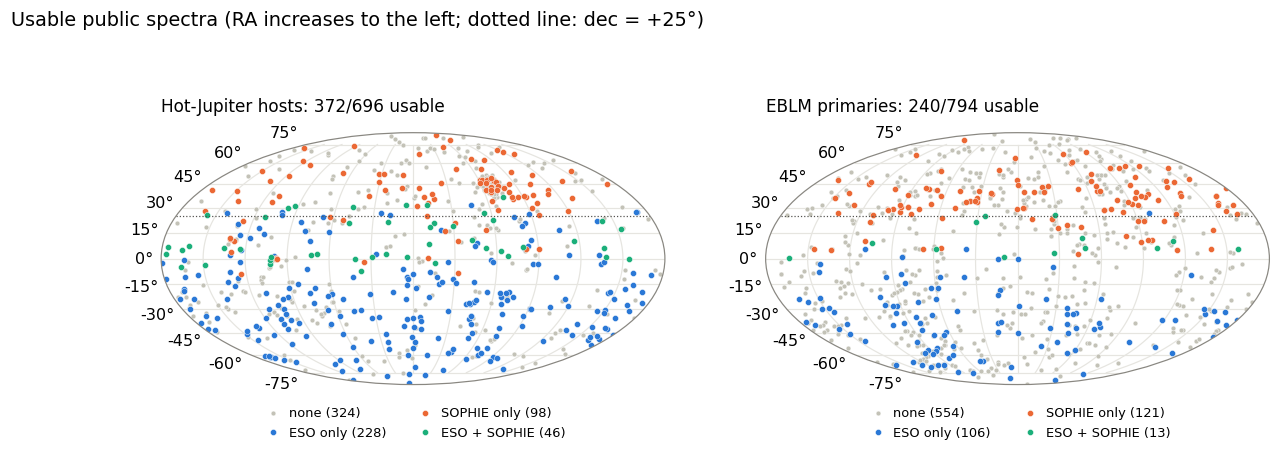

source,ESO + SOPHIE,ESO only,SOPHIE only,none,All
sample,,,,,
EBLM primaries,13,106,121,554,794
Hot-Jupiter hosts,46,228,98,324,696
All,59,334,219,878,1490


In [2]:
cov = []
for sample, f in [('HJ', 'sophie_coverage_hot_jupiters.csv'), ('EBLM', 'sophie_coverage_eblm.csv')]:
    c = pd.read_csv(f'{D}/{f}')
    c['sample'] = sample
    cov.append(c)
cov = pd.concat(cov, ignore_index=True)
cov['source'] = np.select([cov.eso_usable & cov.sophie_usable, cov.eso_usable, cov.sophie_usable],
                          ['ESO + SOPHIE', 'ESO only', 'SOPHIE only'], 'none')
SRC_COL = {'ESO only': COL['EBLM'], 'SOPHIE only': COL['HJ'], 'ESO + SOPHIE': COL['alt'], 'none': COL['mute']}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), subplot_kw={'projection': 'mollweide'})
for ax, sample in zip(axes, ['HJ', 'EBLM']):
    c = cov[cov['sample'] == sample]
    for src in ['none', 'ESO only', 'SOPHIE only', 'ESO + SOPHIE']:
        s = c[c.source == src]
        ra = np.radians(((s.ra + 180) % 360) - 180)
        ax.scatter(-ra, np.radians(s.dec), s=10 if src == 'none' else 16, color=SRC_COL[src],
                   edgecolor='white', linewidth=0.3, label=f'{src} ({len(s)})', zorder=1 if src == 'none' else 2)
    ax.axhline(np.radians(25), color=COL['ink'], lw=0.8, ls=':')
    ax.set_xticklabels([]); ax.grid(True, color='#e6e5e0')
    ax.set_title(f'{SAMPLE_LABEL[sample]}: {c.source.ne("none").sum()}/{len(c)} usable', loc='left', fontsize=11, pad=14)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.04), ncol=2, fontsize=8.5, handletextpad=0.2)
fig.suptitle('Usable public spectra (RA increases to the left; dotted line: dec = +25°)', x=0.02, ha='left', y=1.02)
plt.show()

pd.crosstab(cov['sample'].map(SAMPLE_LABEL), cov.source, margins=True)

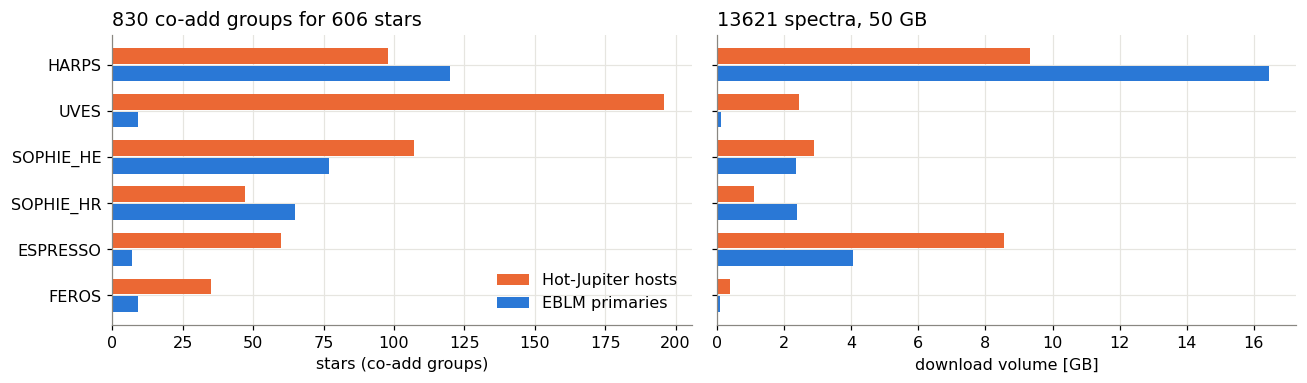

In [3]:
if manifest is not None:
    m = manifest.merge(targets[['target_id', 'sample']], on='target_id')
    g = m.groupby(['instrument', 'sample']).agg(groups=('group', 'nunique'), gb=('size_mb', lambda x: x.sum() / 1024))
    g = g.unstack('sample').fillna(0)
    order = g['groups'].sum(axis=1).sort_values().index
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    y = np.arange(len(order)); h = 0.38
    for k, (sample, off) in enumerate([('HJ', h / 2), ('EBLM', -h / 2)]):
        a1.barh(y + off, g['groups'][sample].reindex(order), height=h - 0.04, color=COL[sample],
                label=SAMPLE_LABEL[sample])
        a2.barh(y + off, g['gb'][sample].reindex(order), height=h - 0.04, color=COL[sample])
    a1.set_yticks(y, order); a1.set_xlabel('stars (co-add groups)'); a1.legend(loc='lower right')
    a2.set_xlabel('download volume [GB]')
    a1.set_title(f'{m.group.nunique()} co-add groups for {m.target_id.nunique()} stars', loc='left')
    a2.set_title(f'{len(m)} spectra, {m.size_mb.sum() / 1024:.0f} GB', loc='left')
    plt.tight_layout(); plt.show()

## 2. Fit quality

Every co-add is fitted separately. The cuts (`eblm_feh.quality_cuts`) require S/N ≥ 20, vbroad ≤ 40 km/s, a fit
away from the grid edges, TIC Teff < 7300 K, and a spectroscopic Teff within 500 K of the TIC value.

752/786 co-adds pass; failures by instrument:
instrument
ESPRESSO_R140000    8
FEROS_R48000        2
HARPS_R115000       4
HARPS_R80000        1
SOPHIE_HE_R39000    5
SOPHIE_HR_R75000    4
UVES_R107000        6
UVES_R52000         1
UVES_R57000         3


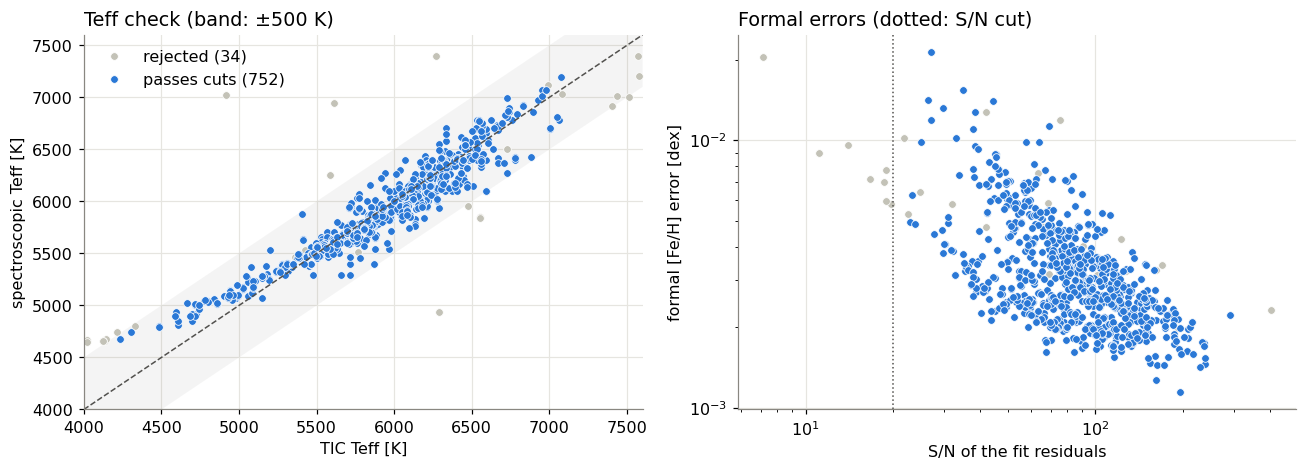

In [4]:
if fits_all is not None:
    f = fits_all.merge(targets[['target_id', 'tic_teff', 'sample']].rename(columns={'target_id': 'name'}), on='name')
    print(f"{f.ok.sum()}/{len(f)} co-adds pass; failures by instrument:")
    print(f[~f.ok].groupby('instrument').size().to_string())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
    for ok, c, lab in [(False, COL['mute'], 'rejected'), (True, COL['EBLM'], 'passes cuts')]:
        s = f[f.ok == ok]
        a1.plot(s.tic_teff, s.teff, 'o', ms=5, color=c, mec='white', mew=0.5, label=f'{lab} ({len(s)})')
        a2.plot(s.snr, s.feh_err, 'o', ms=5, color=c, mec='white', mew=0.5)
    lo, hi = 4000, 7600
    a1.plot([lo, hi], [lo, hi], color=COL['ink'], lw=1, ls='--')
    a1.fill_between([lo, hi], [lo - 500, hi - 500], [lo + 500, hi + 500], color=COL['ink'], alpha=0.06, lw=0)
    a1.set_xlim(lo, hi); a1.set_ylim(lo, hi)
    a1.set_xlabel('TIC Teff [K]'); a1.set_ylabel('spectroscopic Teff [K]'); a1.legend(loc='upper left')
    a1.set_title('Teff check (band: ±500 K)', loc='left')
    a2.set_xscale('log'); a2.set_yscale('log'); a2.axvline(20, color=COL['ink'], lw=1, ls=':')
    a2.set_xlabel('S/N of the fit residuals'); a2.set_ylabel('formal [Fe/H] error [dex]')
    a2.set_title('Formal errors (dotted: S/N cut)', loc='left')
    plt.tight_layout(); plt.show()

## 3. Zero point and instrument consistency

The raw PHOENIX scale is anchored to ARES+MOOG/SME analyses: SWEET-Cat's homogeneous hot-Jupiter hosts plus the EBLM
literature calibrators. If the pooled zero point and the two separate ones disagree, the calibration depends on which
sample it comes from.

,zero point,error,n,star-to-star rms
pooled,+0.222,0.008,270.000000,0.112
SWEET-Cat,+0.226,0.008,256.000000,0.110
EBLM literature,+0.206,0.014,14.000000,0.144
"pooled, Teff-dependent",+nan,0.023,270.000000,0.082


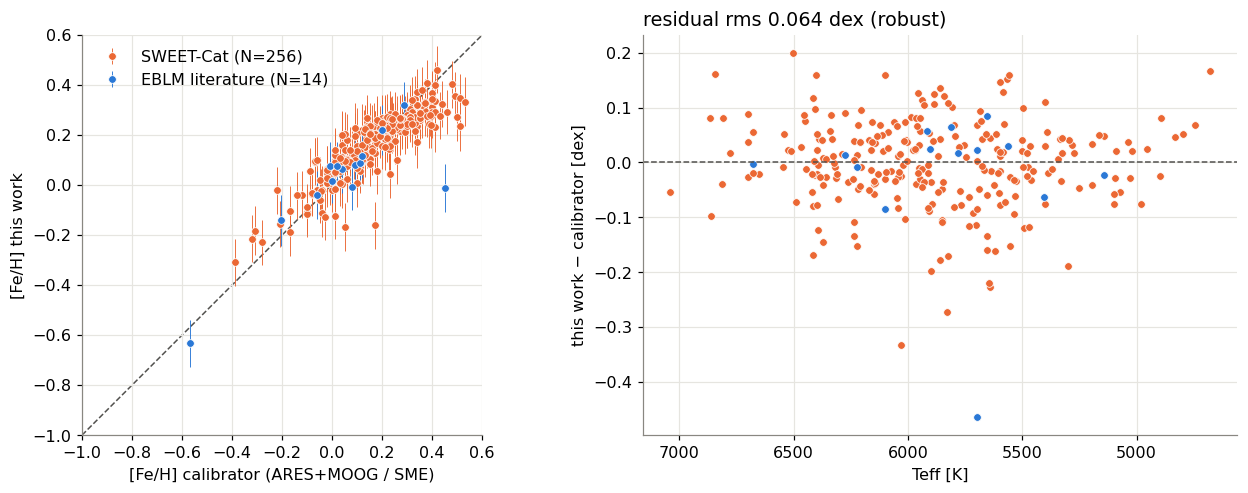

In [5]:
if final is not None:
    zps = json.load(open(f'{RES}/zero_points.json'))
    display(pd.DataFrame(zps).T.rename(columns={'zp': 'zero point', 'zp_err': 'error', 'scatter': 'star-to-star rms'})
            .style.format('{:+.3f}', subset=['zero point']).format('{:.3f}', subset=['error', 'star-to-star rms']))
    c = final.dropna(subset=['cal_feh'])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
    for src, col in [('SWEET-Cat', COL['HJ']), ('EBLM literature', COL['EBLM'])]:
        s = c[c.cal_source == src]
        a1.errorbar(s.cal_feh, s.feh, yerr=s.feh_err, fmt='o', ms=5, color=col, mec='white', mew=0.5,
                    elinewidth=0.6, label=f'{src} (N={len(s)})')
        a2.plot(s.teff, s.feh - s.cal_feh, 'o', ms=5, color=col, mec='white', mew=0.5)
    one_to_one(a1)
    a1.set_xlabel('[Fe/H] calibrator (ARES+MOOG / SME)'); a1.set_ylabel('[Fe/H] this work'); a1.legend(loc='upper left')
    a2.axhline(0, color=COL['ink'], lw=1, ls='--')
    a2.set_xlabel('Teff [K]'); a2.set_ylabel('this work − calibrator [dex]'); a2.invert_xaxis()
    a2.set_title(f'residual rms {robust_std(c.feh - c.cal_feh):.3f} dex (robust)', loc='left')
    plt.tight_layout(); plt.show()

### Teff-dependent zero point

The raw offset (calibrator − this work) is not constant: about −0.15 dex at 4700 K, rising to about +0.24 dex at
~5600 K and flat above. `combine` fits it with a straight line that rises up to a break temperature and is constant
above it (robust Huber fit, break fitted too; `results/zero_point_teff.csv` holds the curve and its bootstrap error).
Outside the calibrators' Teff range it is held at the edge value, and those stars are flagged `teff_outside_calib`.
The binned medians (`zero_point_teff_bins.csv`) are shown only as a check of the fit. The constant zero point is kept
as `feh_constzp`.

In [6]:
if final is not None and os.path.exists(f'{RES}/zero_point_teff_bins.csv'):
    zg = pd.read_csv(f'{RES}/zero_point_teff.csv')         # fitted curve
    zb = pd.read_csv(f'{RES}/zero_point_teff_bins.csv')    # binned medians, for checking the fit
    zt = zps['pooled, Teff-dependent']
    c = final.dropna(subset=['cal_feh']).assign(raw_resid=lambda d: d.cal_feh - d.feh_raw)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
    for src, col in [('SWEET-Cat', COL['HJ']), ('EBLM literature', COL['EBLM'])]:
        s = c[c.cal_source == src]
        a1.plot(s.teff, s.raw_resid, 'o', ms=4.5, color=col, mec='white', mew=0.5, alpha=0.8, label=f'{src} ({len(s)})')
    a1.errorbar(zb.teff, zb.zp, yerr=zb.zp_err, xerr=[zb.teff - zb.teff_lo, zb.teff_hi - zb.teff], fmt='s', ms=4.5,
                color=COL['mute'], elinewidth=0.8, capsize=0, label='binned medians (check)')
    a1.fill_between(zg.teff, zg.zp - zg.zp_err, zg.zp + zg.zp_err, color='k', alpha=0.15, lw=0)
    a1.plot(zg.teff, zg.zp, 'k-', lw=1.8,
            label=f"adopted: {zt['zp']:+.3f} above {zt['teff_break']:.0f} K, {zt['slope_per_100K']:+.3f}/100 K below")
    a1.axhline(zps['pooled']['zp'], color=COL['mute'], ls='--', lw=1.2, label=f"constant: {zps['pooled']['zp']:+.3f}")
    a1.set(xlabel='Teff (this work) [K]', ylabel='calibrator − raw [Fe/H] [dex]', title='raw offset vs Teff')
    a1.invert_xaxis(); a1.legend(fontsize=8.5)
    # what the choice of zero point does to the final values
    a2.plot(final.teff, final.feh - final.feh_constzp, 'o', ms=3.5, color=COL['alt'], mec='none', alpha=0.7)
    a2.axhline(0, color='k', lw=0.8, ls='--')
    a2.set(xlabel='Teff [K]', ylabel='Teff-dependent − constant zero point [dex]',
           title=f"scatter vs calibrators: {zps['pooled']['scatter']:.3f} → {zt['scatter']:.3f} dex")
    a2.invert_xaxis()
    plt.tight_layout(); plt.show()
    print(f"{int(final.teff_outside_calib.sum())} stars outside the calibrated Teff range "
          f"({zt['teff_min']:.0f}-{zt['teff_max']:.0f} K)")
else:
    print('no zero_point_teff_bins.csv: re-run the combine stage with the current metallicity_pipeline.py')


no zero_point_teff_bins.csv: re-run the combine stage with the current metallicity_pipeline.py


,instrument,vs,n,median_diff,robust_rms
0,ESPRESSO_R140000,HARPS_R115000,27,-0.021,0.012
1,FEROS_R48000,HARPS_R115000,13,+0.027,0.024
2,HARPS_R80000,HARPS_R115000,8,+0.016,0.018
3,SOPHIE_HE_R39000,HARPS_R115000,16,-0.044,0.057
4,SOPHIE_HR_R75000,HARPS_R115000,14,-0.035,0.023
5,UVES_R107000,HARPS_R115000,37,-0.000,0.011
6,UVES_R42000,HARPS_R115000,3,+0.015,0.022
7,UVES_R46000,HARPS_R115000,0,+nan,nan
8,UVES_R52000,HARPS_R115000,0,+nan,nan
9,UVES_R57000,HARPS_R115000,7,+0.005,0.013


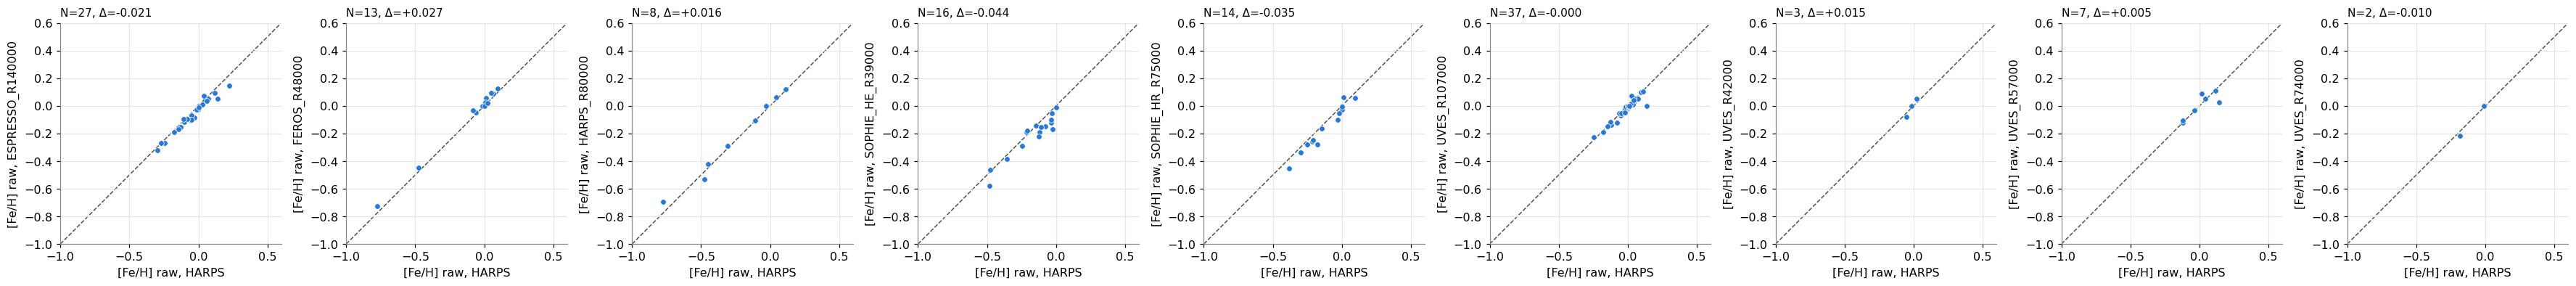

In [7]:
if fits_all is not None:
    off = pd.read_csv(f'{RES}/instrument_offsets.csv')
    display(off.style.format({'median_diff': '{:+.3f}', 'robust_rms': '{:.3f}'}))
    ok = fits_all[fits_all.ok]
    p = ok.pivot_table(index='name', columns='instrument', values='feh')
    ref = 'HARPS_R115000'
    others = [c for c in p.columns if c != ref and ref in p and p[[ref, c]].dropna().shape[0] > 0]
    if others:
        fig, axes = plt.subplots(1, len(others), figsize=(3.6 * len(others), 3.8), squeeze=False)
        for ax, col in zip(axes[0], others):
            d = p[[ref, col]].dropna()
            ax.plot(d[ref], d[col], 'o', ms=5, color=COL['EBLM'], mec='white', mew=0.5)
            one_to_one(ax)
            ax.set_xlabel(f'[Fe/H] raw, {ref.split("_")[0]}'); ax.set_ylabel(f'[Fe/H] raw, {col}')
            ax.set_title(f'N={len(d)}, Δ={np.median(d[col] - d[ref]):+.3f}', loc='left', fontsize=10)
        plt.tight_layout(); plt.show()

## 4. PAWS sanity check

PAWS (Freckelton et al. 2024, BEBOP V) is the method behind most published EBLM-primary metallicities, so it is the
natural independent check. Two questions:

1. **Does the re-run reproduce the published PAWS values?** This tests whether the PAWS installation and wrapper
   (`hpc/paws_pipeline.py`) are faithful.
2. **Do PAWS and the PHOENIX fit agree on the same spectra?** This tests the method. With the Teff-dependent zero
   point, this work agrees with published PAWS to within 0.01 dex in the median for SOPHIE stars, but sits ~0.26 dex above
   it for HARPS stars; the subsection after the plots shows that the HARPS offset comes from the published values.

### How PAWS differs from this work

The two analyses share only the spectra (and not even the co-adds). Everything else differs:

| | This work (`eblm_feh`) | PAWS (iSpec) |
|---|---|---|
| **Approach** | One step: least-squares fit of the observed pixels against synthetic spectra | Two steps: (1) equivalent widths (EWs) of Fe I and Fe II lines; (2) spectral synthesis of selected line regions, started from the EW result |
| **Model atmospheres / spectra** | PHOENIX-ACES (Husser et al. 2013), a pre-computed grid of spectra (Teff 4200–7400 K, logg 3.5–5.0, [Fe/H] −1.5 to +0.5 in 0.5 dex steps), interpolated | ATLAS9 atmospheres; spectra computed on the fly with WIDTH (EWs) and SPECTRUM (synthesis) from the Gaia-ESO line list |
| **Wavelengths used** | Six Fe-line-rich windows, 5040–6260 Å, avoiding Mg b, Na D, Hα and strong telluric bands | 4200–6800 Å; individual Fe lines (EW step) and the Gaia-ESO line regions (synthesis step) |
| **Which pixels count** | Only pixels where PHOENIX reproduces the Kitt Peak solar atlas to within 3%, so badly modelled lines are dropped and the fit is close to differential with respect to the Sun | The lines and regions of the Gaia-ESO selections built into iSpec, not tuned to PHOENIX or to our data |
| **Continuum** | A cubic polynomial per window, fitted together with the stellar parameters | Normalised before the analysis, so continuum errors pass straight into the line depths |
| **Free parameters** | Teff, [Fe/H], line broadening (one kernel for rotation + macroturbulence), RV. **logg fixed** to the TIC/Gaia value (96% of stars) | EW step: Teff, logg, [M/H], microturbulence from excitation and ionisation balance. Synthesis: Teff, **logg**, [M/H], v sin i free. **logg is spectroscopic** |
| **Microturbulence** | Whatever is built into the PHOENIX grid; not fitted | Fitted (EW step) |
| **Metallicity reported** | [Fe/H] (the scaled-solar abundance that best matches the windows) | [M/H] (overall metallicity) from the synthesis step |
| **Calibration** | Empirical: a Teff-dependent zero point to ARES+MOOG/SME values (SWEET-Cat and the EBLM literature) | None; absolute, as the models give it |
| **Co-adding** | Our own: RV from cross-correlation, rest-frame shift, inverse-variance mean with 5σ clipping, ≤ 50 exposures, in-transit exposures dropped | PAWS's `coadding.py`, on exposures with S/N ≥ 20 |
| **Cost** | ~2 s per co-add | ~4 h per co-add (mostly the synthesis step) |

**What this means for the comparison:**

* **A constant offset says little about either method alone.** This work is tied to ARES+MOOG by construction, and PAWS
  is not calibrated at all. A median offset between them measures how far the PAWS scale is from ARES+MOOG (for our
  SOPHIE re-run, this work − PAWS ≈ −0.06 dex). The star-to-star scatter is the real test of both methods.
* **Temperature and metallicity move together.** In both methods a hotter Teff needs stronger lines, so a higher
  [Fe/H], to match the same spectrum. Against published PAWS, a 100 K difference in Teff comes with about 0.04 dex
  in [Fe/H]. Points far from the 1:1 line usually also disagree in Teff; check that before blaming the metallicity.
* **Fixed vs fitted logg.** Fixing logg removes the Teff–logg–[M/H] degeneracy that a purely spectroscopic analysis
  has to fight. PAWS fits logg from Fe I/Fe II ionisation balance and line wings. When that goes wrong it sends Teff
  and [M/H] with it: our HARPS re-run has fits with logg = 0 and logg ≈ 2.6 for dwarf stars, which is this failure.
* **Continuum handling.** A tilted or badly normalised continuum biases PAWS directly, because it measures line depths
  against a fixed continuum, while our per-window polynomial absorbs smooth continuum errors. The published HARPS
  values with continuum problems (J1928-38, below) are an example.
* **[M/H] vs [Fe/H].** For stars with scaled-solar abundances these are the same within a few hundredths of a dex.
  They differ for alpha-enhanced (typically metal-poor, thick-disc) stars, where [M/H] from the synthesis step sits
  above [Fe/H]. Expect that in the few EBLMs below [Fe/H] ≈ −0.5.
* **Different lines.** Our windows are a subset of the PAWS range, and the solar mask drops the lines PHOENIX models
  poorly, so the two methods weight different parts of the spectrum. That is useful for an independent check, but it
  means some scatter between them (~0.1 dex) is expected even when both are right.

87 PAWS results for 72 stars (0 groups failed or not run)


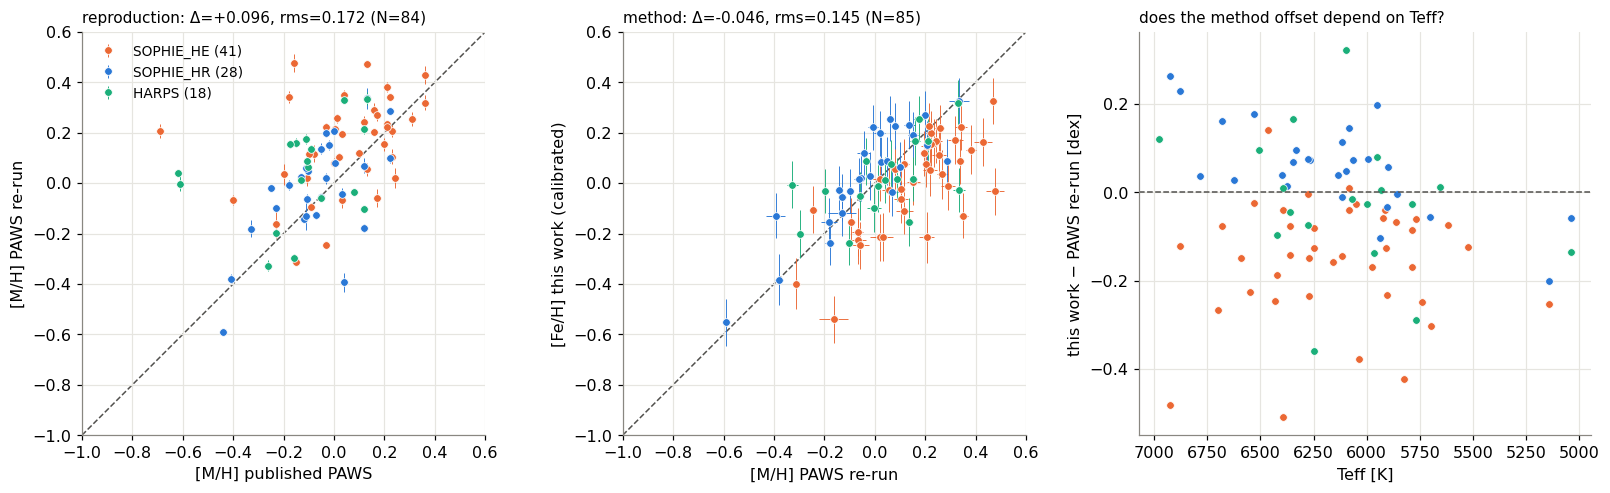

In [8]:
if paws is not None and final is not None:
    pw = paws.dropna(subset=['synth_MH']).merge(final[['target_id', 'feh', 'feh_err', 'feh_raw', 'teff',
                                                       'paws_lit_feh']], on='target_id', how='left')
    pw['paws_err'] = pw.get('synth_MH_err', np.nan)
    print(f'{len(pw)} PAWS results for {pw.target_id.nunique()} stars '
          f'({paws.synth_MH.isna().sum()} groups failed or not run)')
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    inst_col = {'SOPHIE_HE': COL['HJ'], 'SOPHIE_HR': COL['EBLM'], 'HARPS': COL['alt']}
    for inst, col in inst_col.items():
        s = pw[pw.instrument == inst]
        if s.empty:
            continue
        kw = dict(fmt='o', ms=5, color=col, mec='white', mew=0.5, elinewidth=0.6, label=f'{inst} ({len(s)})')
        axes[0].errorbar(s.paws_lit_feh, s.synth_MH, yerr=s.paws_err, **kw)
        axes[1].errorbar(s.synth_MH, s.feh, xerr=s.paws_err, yerr=s.feh_err, **kw)
        axes[2].plot(s.teff, s.feh - s.synth_MH, 'o', ms=5, color=col, mec='white', mew=0.5)
    for ax in axes[:2]:
        one_to_one(ax)
    d0 = (pw.synth_MH - pw.paws_lit_feh).dropna(); d1 = (pw.feh - pw.synth_MH).dropna()
    axes[0].set_xlabel('[M/H] published PAWS'); axes[0].set_ylabel('[M/H] PAWS re-run')
    axes[0].set_title(f'reproduction: Δ={d0.median():+.3f}, rms={robust_std(d0):.3f} (N={len(d0)})', loc='left',
                      fontsize=10)
    axes[0].legend(loc='upper left', fontsize=9)
    axes[1].set_xlabel('[M/H] PAWS re-run'); axes[1].set_ylabel('[Fe/H] this work (calibrated)')
    axes[1].set_title(f'method: Δ={d1.median():+.3f}, rms={robust_std(d1):.3f} (N={len(d1)})', loc='left',
                      fontsize=10)
    axes[2].axhline(0, color=COL['ink'], lw=1, ls='--'); axes[2].invert_xaxis()
    axes[2].set_xlabel('Teff [K]'); axes[2].set_ylabel('this work − PAWS re-run [dex]')
    axes[2].set_title('does the method offset depend on Teff?', loc='left', fontsize=10)
    plt.tight_layout(); plt.show()

### Why HARPS stars disagree with the published PAWS values

For HARPS stars, this work and our PAWS re-run agree with each other but both sit about 0.2 dex above the published
PAWS values. Several published HARPS entries are themselves inconsistent: EBLM J1928-38 is listed at 5227 K / −0.39
(Davis+2026) and 5738 K / +0.18 (the Stevenson+2026 re-analysis, made because the earlier spectra had continuum
problems), and J0608-59 at both −0.27 and +0.01. The plot shows each published value against ours. Points far
below the line with a published Teff well below ours point to that continuum problem in the literature value, not here.
Separately, our HARPS PAWS Teff/logg are unreliable (several fits run hot with logg < 3.6; two hit logg = 0), so use
the HARPS PAWS re-run for [M/H] only.

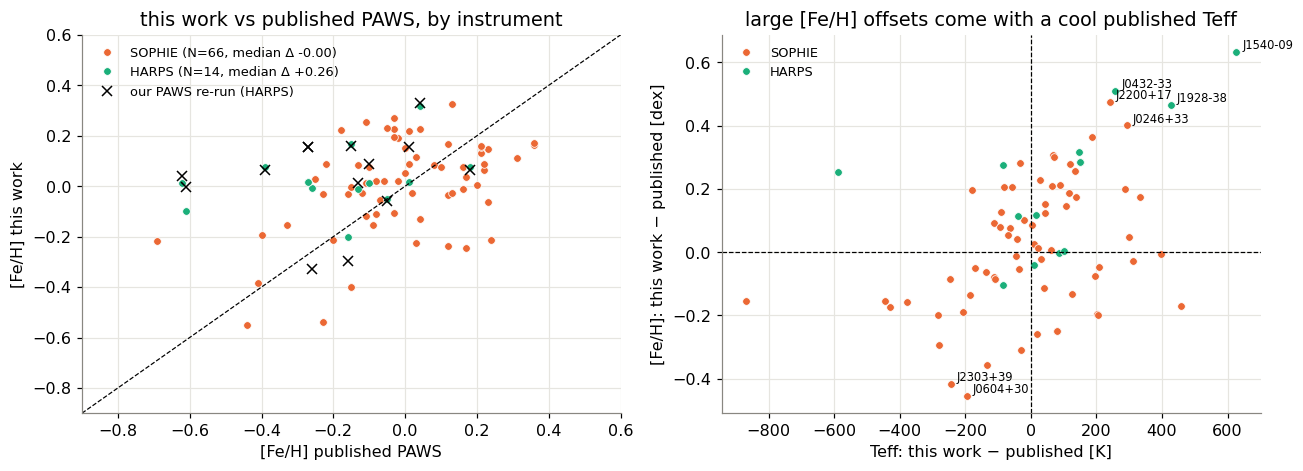

In [9]:
if paws is not None and final is not None:
    lit = pd.read_csv(f'{D}/eblm_literature_feh.csv')
    lit = lit[lit.method.str.startswith('PAWS')].copy()
    short = targets[targets['sample'] == 'EBLM'].assign(s=lambda d: d.name.str.replace('EBLM ', '')) \
        .drop_duplicates('s').set_index('s').target_id
    lit['target_id'] = lit.name.map(short)
    lit['family'] = lit.instrument.str.split(' ').str[0]
    m = lit.merge(final[['target_id', 'feh', 'teff']].rename(columns={'feh': 'feh_tw', 'teff': 'teff_tw'}), on='target_id')
    pw = paws[paws.instrument == 'HARPS'].set_index('target_id').synth_MH
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
    for fam, col in [('SOPHIE', COL['HJ']), ('HARPS', COL['alt']), ('CORALIE', COL['mute'])]:
        s = m[m.family == fam]
        if s.empty: continue
        d = s.feh_tw - s.feh
        a1.plot(s.feh, s.feh_tw, 'o', ms=5, color=col, mec='white', mew=0.5,
                label=f'{fam} (N={len(s)}, median Δ {d.median():+.2f})')
        a2.plot(s.teff_tw - s.teff, d, 'o', ms=5, color=col, mec='white', mew=0.5, label=fam)
    h = m[m.family == 'HARPS'].assign(ours=lambda d: d.target_id.map(pw))
    a1.plot(h.feh, h.ours, 'x', color='k', ms=6, label='our PAWS re-run (HARPS)')
    lim = [-0.9, 0.6]; a1.plot(lim, lim, 'k--', lw=0.8)
    a1.set(xlim=lim, ylim=lim, xlabel='[Fe/H] published PAWS', ylabel='[Fe/H] this work',
           title='this work vs published PAWS, by instrument'); a1.legend(fontsize=8.5)
    for _, r in m[(m.feh_tw - m.feh).abs() > 0.4].iterrows():
        a2.annotate(r['name'], (r.teff_tw - r.teff, r.feh_tw - r.feh), fontsize=7.5, xytext=(4, 2),
                    textcoords='offset points')
    a2.axhline(0, color='k', lw=0.8, ls='--'); a2.axvline(0, color='k', lw=0.8, ls='--')
    a2.set(xlabel='Teff: this work − published [K]', ylabel='[Fe/H]: this work − published [dex]',
           title='large [Fe/H] offsets come with a cool published Teff'); a2.legend(fontsize=8.5)
    plt.tight_layout(); plt.show()


### Summary: how and why this work disagrees with PAWS

**How.** On average the two agree: this work is +0.03 dex above published PAWS over 71 EBLMs (−0.01 dex for the 60
SOPHIE stars). The disagreement is star by star, and for the HARPS stars:

| Comparison | n | median Δ[Fe/H] | robust rms |
|---|---|---|---|
| this work − published PAWS (all) | 71 | +0.03 | 0.23 |
| this work − published PAWS (HARPS stars) | 11 | +0.18 | 0.10 |
| this work − our PAWS re-run (SOPHIE) | 58 | −0.07 | 0.16 |

(Nov 2026 run with the smooth Teff-dependent zero point; the cell below recomputes these from the current results.)

**Why.**

1. **Teff disagreements drive most of the scatter.** Teff differs by 150–190 K (rms) between the methods, and a
   hotter Teff needs a higher [Fe/H] to match the same lines. Against our PAWS re-run the [Fe/H] and Teff differences
   correlate with r = 0.76; removing that term cuts the scatter from 0.16 to 0.09 dex. The root is logg: this work fixes
   it to TIC/Gaia, PAWS fits it, and PAWS logg comes out 0.23 dex below TIC in the median.
2. **Many published values are imprecise.** Published PAWS errors have a median of 0.14 dex, and 35% are ≥ 0.2 dex
   (mostly low-S/N SOPHIE HE). Divided by the combined error bars, the differences scatter only 1.1–1.3× the expected
   amount, so most of the disagreement is within the stated uncertainties.
3. **The HARPS offset is in the published values.** This work and our own HARPS PAWS re-run agree (−0.03 dex); several
   published HARPS values carry a continuum problem (a too-cool Teff with a low [Fe/H]; see the previous subsection).
4. **Calibration sets the small constant offset.** This work is tied to ARES+MOOG and PAWS is not calibrated; our PAWS
   re-run also leaves [M/H] free in the synthesis step and runs +0.085 dex above the published values.
5. **Smaller effects:** [M/H] vs [Fe/H] for alpha-enhanced stars, different lines and continuum handling, different
   co-adds.

**For the main result** neither method looks broken. Hot-Jupiter hosts and EBLMs go through the same pipeline, so
method offsets largely cancel in their comparison (section 5).

In [ ]:
if paws is not None and final is not None:
    rr = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
    lit = pd.read_csv(f'{D}/eblm_literature_feh.csv')
    lit = lit[lit.method.str.startswith('PAWS')].assign(family=lambda d: d.instrument.str.split(' ').str[0])
    pub = lit.groupby('name').agg(pub_teff=('teff', 'mean'), pub_feh=('feh', 'mean'), pub_err=('feh_err', 'mean'),
                                  family=('family', 'first'))
    d = final.assign(short=final.name.str.replace('EBLM ', '')).merge(pub, left_on='short', right_index=True)
    d['dfeh'], d['dteff'] = d.feh - d.pub_feh, d.teff - d.pub_teff
    d['pull'] = d.dfeh / np.hypot(d.feh_err, d.pub_err)
    rows = [('this work − published PAWS', k, g) for k, g in [('all', d)] + list(d.groupby('family'))]
    pw = paws.assign(family=paws.instrument.str.split('_').str[0])
    s = (pw[(pw.family == 'SOPHIE') & (pw.synth_logg > 3)].groupby('target_id')
         .agg(paws_feh=('synth_MH', 'mean'), paws_teff=('synth_teff', 'mean'), paws_logg=('synth_logg', 'mean')))
    e = final.set_index('target_id').join(s, how='inner')
    e['dfeh'], e['dteff'] = e.feh - e.paws_feh, e.teff - e.paws_teff
    rows.append(('this work − our PAWS re-run', 'SOPHIE', e))
    out = pd.DataFrame([{'comparison': c, 'stars': k, 'n': len(g), 'median Δ[Fe/H]': g.dfeh.median(),
                         'rms Δ[Fe/H]': rr(g.dfeh), 'median ΔTeff': g.dteff.median(), 'rms ΔTeff': rr(g.dteff),
                         'corr(Δ[Fe/H], ΔTeff)': np.corrcoef(g.dfeh, g.dteff)[0, 1],
                         'pull rms': rr(g.pull) if 'pull' in g else np.nan} for c, k, g in rows])
    display(out.style.format({'median Δ[Fe/H]': '{:+.3f}', 'rms Δ[Fe/H]': '{:.3f}', 'median ΔTeff': '{:+.0f}',
                              'rms ΔTeff': '{:.0f}', 'corr(Δ[Fe/H], ΔTeff)': '{:.2f}', 'pull rms': '{:.2f}'}, na_rep='')
            .hide(axis='index'))
    slope = np.polyfit(e.dteff, e.dfeh, 1)[0]
    print(f'vs our PAWS re-run: rms {rr(e.dfeh):.3f} dex -> {rr(e.dfeh - slope * e.dteff):.3f} dex after removing the '
          f'Teff-difference term ({100 * slope:+.3f} dex per 100 K); PAWS logg − TIC logg: median '
          f'{(e.paws_logg - e.logg).median():+.2f}')
    print(f'published PAWS errors: median {d.pub_err.median():.2f} dex, {(d.pub_err >= 0.2).mean():.0%} ≥ 0.2 dex')


## 5. Hot-Jupiter hosts vs. EBLM primaries

The comparison this was all for: both samples are measured with the same method, the same zero point and largely the
same instruments, restricted to the same Teff range. The bootstrap gives the median difference and its 95% interval;
the KS test compares the full distributions.

,N HJ,N EBLM,median HJ,median EBLM,HJ − EBLM,95% CI,KS p
all hot-Jupiter hosts,296,209,+0.211,+0.005,+0.206,"[+0.163, +0.234]",1.1e-19
WASP-discovered hosts only,114,209,+0.225,+0.005,+0.220,"[+0.172, +0.246]",4.4e-14


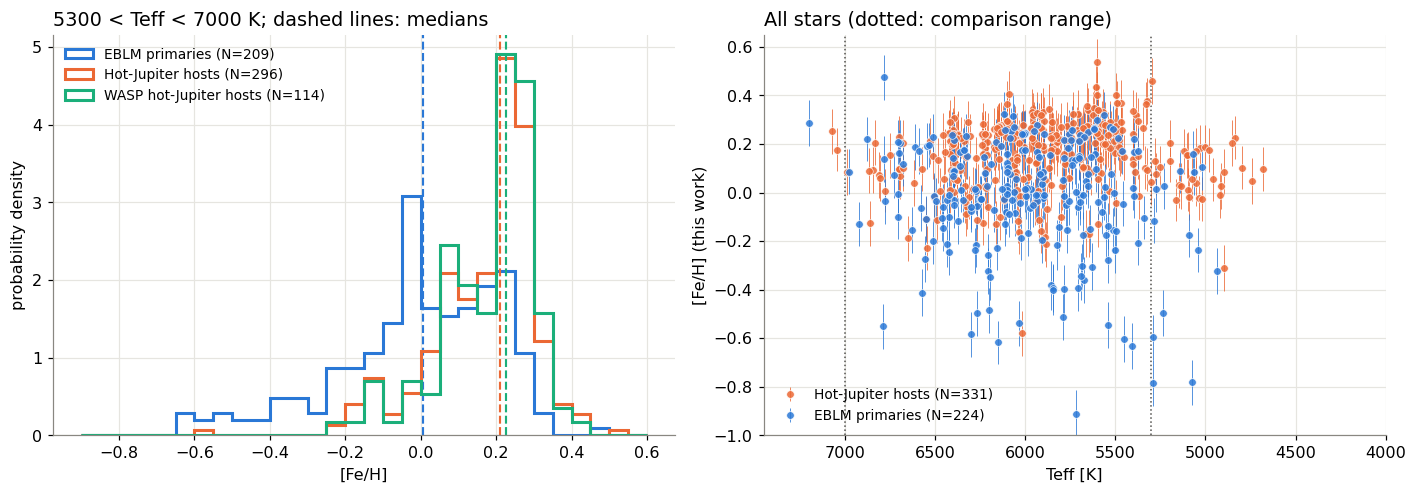

In [10]:
def compare(a, b, n_boot=10000, seed=2):
    a, b = np.asarray(a, float), np.asarray(b, float)
    rng = np.random.default_rng(seed)
    boot = [np.median(rng.choice(a, a.size)) - np.median(rng.choice(b, b.size)) for _ in range(n_boot)]
    return {'N HJ': a.size, 'N EBLM': b.size, 'median HJ': np.median(a), 'median EBLM': np.median(b),
            'HJ − EBLM': np.median(a) - np.median(b),
            '95% CI': f'[{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]',
            'KS p': stats.ks_2samp(a, b).pvalue}

if final is not None:
    s = final[final.teff.between(*TEFF)]
    hj, eb = s[s['sample'] == 'HJ'], s[s['sample'] == 'EBLM']
    wasp = hj[hj.disc_facility.str.contains('WASP', na=False)]
    rows = {'all hot-Jupiter hosts': compare(hj.feh, eb.feh) if len(hj) > 1 and len(eb) > 1 else {},
            'WASP-discovered hosts only': compare(wasp.feh, eb.feh) if len(wasp) > 1 and len(eb) > 1 else {}}
    display(pd.DataFrame(rows).T.style.format({'median HJ': '{:+.3f}', 'median EBLM': '{:+.3f}',
                                               'HJ − EBLM': '{:+.3f}', 'KS p': '{:.2g}'}, na_rep='–'))

    bins = np.arange(-0.9, 0.65, 0.05)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
    for v, col, lab in [(eb.feh, COL['EBLM'], f'EBLM primaries (N={len(eb)})'),
                        (hj.feh, COL['HJ'], f'Hot-Jupiter hosts (N={len(hj)})'),
                        (wasp.feh, COL['alt'], f'WASP hot-Jupiter hosts (N={len(wasp)})')]:
        if len(v) == 0:
            continue
        a1.hist(v, bins=bins, density=True, histtype='step', color=col, lw=2, label=lab)
        a1.axvline(np.median(v), color=col, lw=1.4, ls='--')
    a1.set_xlabel('[Fe/H]'); a1.set_ylabel('probability density'); a1.legend(loc='upper left', fontsize=9)
    a1.set_title(f'{TEFF[0]} < Teff < {TEFF[1]} K; dashed lines: medians', loc='left')
    for sample in ['HJ', 'EBLM']:
        q = final[final['sample'] == sample]
        a2.errorbar(q.teff, q.feh, yerr=q.feh_err, fmt='o', ms=5, color=COL[sample], mec='white', mew=0.5,
                    elinewidth=0.6, alpha=0.85, label=f'{SAMPLE_LABEL[sample]} (N={len(q)})')
    for x in TEFF:
        a2.axvline(x, color=COL['ink'], lw=1, ls=':')
    a2.set_xlim(7450, 4000); a2.set_ylim(-1.0, 0.65)
    a2.set_xlabel('Teff [K]'); a2.set_ylabel('[Fe/H] (this work)'); a2.legend(loc='lower left', fontsize=9)
    a2.set_title('All stars (dotted: comparison range)', loc='left')
    plt.tight_layout(); plt.show()

In [11]:
# the table behind the plots: one row per star
if final is not None:
    cols = ['name', 'sample', 'feh', 'feh_err', 'teff', 'logg', 'vbroad', 'snr_best', 'n_spectra', 'instruments',
            'cal_feh', 'paws_lit_feh', 'disc_facility']
    display(final[cols].sort_values(['sample', 'name']).round(3).reset_index(drop=True))

,name,sample,feh,feh_err,teff,logg,vbroad,snr_best,n_spectra,instruments,cal_feh,paws_lit_feh,disc_facility
0,06493-00315,EBLM,-0.146,0.094,6455.390,4.395,16.635,45.532,1,FEROS_R48000,NaN,NaN,WASP (EBLM)
1,3473-673-1,EBLM,-0.032,0.095,6074.522,4.024,33.137,26.451,1,SOPHIE_HE_R39000,NaN,NaN,WASP (EBLM)
2,BD-08 1175,EBLM,-0.188,0.088,6024.878,4.298,5.353,145.415,2,HARPS_R115000+HARPS_R80000,NaN,NaN,WASP (EBLM)
3,CD-27 2812,EBLM,0.145,0.093,6226.251,4.050,9.207,178.882,1,HARPS_R80000,NaN,NaN,WASP (EBLM)
4,CD-82 293,EBLM,0.192,0.094,6543.995,4.209,11.222,81.409,1,HARPS_R80000,NaN,NaN,WASP (EBLM)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
550,XO-2 N,HJ,0.366,0.089,5328.666,4.322,3.345,46.904,2,SOPHIE_HE_R39000+SOPHIE_HR_R75000,0.40,NaN,XO
551,XO-4,HJ,0.010,0.094,6419.204,4.110,9.725,106.251,1,SOPHIE_HE_R39000,0.03,NaN,Lowell Observatory
552,XO-7,HJ,0.345,0.101,5867.065,4.127,8.068,72.370,1,SOPHIE_HR_R75000,0.40,NaN,XO
553,tau Boo,HJ,0.282,0.086,6235.870,4.250,16.244,138.953,4,HARPS_R115000+SOPHIE_HR_R75000+UVES_R107000+UV...,0.39,NaN,Lick Observatory
